# 03 · Errores típicos con pesos replicados (BRR)

`03_regresion_por_edicion` calcula los errores típicos agrupados por centro: el estimador sándwich que admite que los alumnos de un mismo centro se parecen entre sí. PISA calcula los suyos de otra forma, con 80 pesos replicados (BRR con el ajuste de Fay): repite la estimación con cada peso replicado y mide cuánto varía. Los pesos replicados recogen todo el diseño de la muestra (centros agrupados en estratos, ajustes por no respuesta), así que son el método oficial.

Este notebook repite el modelo principal (las dos especificaciones de `03_regresion_por_edicion`, las cuatro ediciones) con errores BRR y los compara con los agrupados por centro:

* **Validación** (sección 1): la media de matemáticas de España, calculada con BRR, frente a la que publica la OCDE.
* **Errores típicos de las pendientes** (sección 2): de la pendiente común y de las pendientes por perfil.
* **Contrastes** (sección 3): los cuatro que sostienen las conclusiones de `03_regresion_por_edicion`.

Los coeficientes son los mismos con los dos métodos; solo cambia su error. Los valores plausibles se combinan igual en los dos (reglas de Rubin): la varianza de muestreo de cada valor plausible es la agrupada por centro o la de BRR, y se le suma (1 + 1/M) por la varianza entre valores plausibles. Las comprobaciones de robustez y XGBoost siguen con los errores agrupados por centro.

## 0. Configuración

Los pesos replicados no están en la tabla de `02_preparacion_modelo`: `pesos_replicados` (`src/modelo_regresion.py`) los lee de los datos de cada edición (`W_FSTR1` a `W_FSTR80` en 2012, `W_FSTURWT1` a `W_FSTURWT80` después) y los pasa a la escala de `SENWT`, multiplicándolos por `SENWT` / `W_FSTUWT` de cada alumno. Ese cociente es prácticamente constante dentro de cada país-edición (varía menos del 0,1 %), salvo en Reino Unido 2022, donde toma dos valores que difieren un 9,2 %. Como se aplica alumno a alumno, cada réplica queda en la misma escala que el peso con el que se estima el modelo.

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

sys.path.append(os.path.abspath('../../'))   # para importar `src`
from src.modelo_regresion import (COLUMNAS_REPLICAS, cambio_entre_ediciones, contraste_igualdad, estimar_con_rubin, estimar_por_edicion,
                                  pesos_replicados)
from src.pisa_pipeline import rutas_datos_anuales
from src.preparacion_modelo import DE_INTERES, matriz_regresion

pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 30)

EDICIONES = [2012, 2015, 2018, 2022]
INICIO, FINAL = 2012, 2022
PERFIL_REVISADO = 'PRI_URB_MACRO'
RUTA_RAW_BASE = '../../data/raw'
RUTA_PROCESADOS = '../../data/processed'
RUTA_REPORTS = '../../reports'
NOMBRES = {'Indice_Compromiso_Competencia': 'compromiso', 'recursos_estudio': 'recursos de estudio'}
METODOS = {'centro': 'agrupados por centro', 'brr': 'BRR'}
COLORES_EDICION = dict(zip(EDICIONES, plt.cm.Blues(np.linspace(0.4, 0.95, len(EDICIONES)))))

tabla = pd.read_parquet(os.path.join(RUTA_PROCESADOS, 'tabla_modelo_alumno.parquet'))
parametros = pd.read_parquet(os.path.join(RUTA_PROCESADOS, 'parametros_escala.parquet'))
matriz = matriz_regresion(tabla, parametros)
# Los 80 pesos replicados de cada alumno, en la escala de SENWT
replicas = pesos_replicados(RUTA_RAW_BASE, matriz)
poco_representativo = tabla.groupby(['perfil', 'year'])['perfil_poco_representativo'].first()
# Comprobación: SENWT / W_FSTUWT casi constante dentro de cada país-edición
cociente = (matriz['SENWT'] / matriz['W_FSTUWT']).groupby(matriz['pais_edicion'])
print(f'{len(matriz)} alumnos; pesos replicados: {replicas.shape[1]} por alumno, sin huecos: {not replicas.isna().any().any()}')
print(f'Mayor variación relativa de SENWT / W_FSTUWT dentro de un país-edición: {(cociente.max() / cociente.min() - 1).max():.2e}')

298782 alumnos; pesos replicados: 80 por alumno, sin huecos: True
Mayor variación relativa de SENWT / W_FSTUWT dentro de un país-edición: 9.19e-02


## 1. Validación con la media de España

Antes de usar `mco_brr` en la regresión, se calcula con él algo que la OCDE publica: la media de matemáticas de España con todos sus alumnos, `W_FSTUWT` y los cinco o diez valores plausibles. Es una regresión con solo la constante. Si coincide con la cifra oficial, el cálculo de las réplicas, el ajuste de Fay y la combinación con los valores plausibles están bien. Las cifras oficiales (media y error típico, informes PISA de la OCDE de cada edición) están escritas a mano en `PUBLICADO_OCDE`.

In [2]:
# Media de matemáticas de España y su error típico según los informes de la OCDE
PUBLICADO_OCDE = {2012: (484, 1.9), 2015: (486, 2.2), 2018: (481, 1.5)}
filas = []
for edicion, (media_oficial, error_oficial) in PUBLICADO_OCDE.items():
    valores_plausibles = [f'PV{numero}MATH' for numero in range(1, 6 if edicion == 2012 else 11)]
    # Todos los alumnos de España con el peso oficial: debe reproducir la cifra publicada
    alumnos = pd.read_parquet(rutas_datos_anuales(RUTA_RAW_BASE, edicion)[0], columns=['CNT', 'W_FSTUWT'] + valores_plausibles + COLUMNAS_REPLICAS[edicion])
    alumnos = alumnos[alumnos['CNT'] == 'ESP'].reset_index(drop=True)
    replicas_espana = alumnos[COLUMNAS_REPLICAS[edicion]].set_axis([f'replica_{numero}' for numero in range(1, 81)], axis=1)
    # Regresión sobre una constante = media ponderada; su error típico sale de BRR
    media, _ = estimar_con_rubin(alumnos, pd.DataFrame({'constante': 1.0}, index=alumnos.index), peso_col='W_FSTUWT', replicas=replicas_espana)
    filas.append({'edicion': edicion, 'alumnos': len(alumnos), 'media': media['coeficiente'].iloc[0], 'error_tipico_brr': media['error_tipico'].iloc[0],
                  'media_ocde': media_oficial, 'error_tipico_ocde': error_oficial})
display(pd.DataFrame(filas).set_index('edicion').round(2))

,alumnos,media,error_tipico_brr,media_ocde,error_tipico_ocde
edicion,,,,,
2012,25313,484.32,1.90,484,1.9
2015,6736,485.84,2.15,486,2.2
2018,35943,481.39,1.46,481,1.5


**Qué se ve.** La media y el error típico de España coinciden con los publicados por la OCDE en las tres ediciones: 484,32 (1,90) en 2012, 485,84 (2,15) en 2015 y 481,39 (1,46) en 2018, frente a 484 (1,9), 486 (2,2) y 481 (1,5). El cálculo de BRR es, por tanto, el de PISA.

## 2. Errores típicos de las pendientes

Se estiman las dos especificaciones de `03_regresion_por_edicion` con los dos métodos. Para cada pendiente de interés (la común y las de cada perfil, en las cuatro ediciones) se compara el error típico BRR con el agrupado por centro. Un cociente BRR / centro por encima de 1 quiere decir que el error agrupado por centro se queda corto.

Mayor diferencia entre los coeficientes de los dos métodos: 2.24e-11 puntos


**Pendiente común: coeficiente y error típico con cada método**

coeficiente  centro    brr  cociente
variable            year                                      
compromiso          2012       10.639   0.511  0.496     0.970
                    2015        9.844   0.442  0.450     1.018
                    2018       11.513   0.489  0.457     0.935
                    2022       12.120   0.445  0.445     0.999
recursos de estudio 2012        5.444   0.525  0.500     0.951
                    2015        5.617   0.569  0.558     0.981
                    2018        4.927   0.577  0.589     1.022
                    2022        5.901   0.465  0.452     0.972

**Cociente BRR / centro de los errores típicos de las pendientes por perfil**

count    min    50%    max
variable            year                            
compromiso          2012   15.0  0.786  1.003  1.113
                    2015   15.0  0.920  1.006  1.076
                    2018   15.0  0.925  0.998  1.206
                    2022   15.0  0.862  1.009  1.145
recursos de estudio 2012   15.0  0.941  0.992  1.040
                    2015   15.0  0.897  1.009  1.050
                    2018   15.0  0.834  0.978  1.207
                    2022   15.0  0.855  0.969  1.305

Pendientes por perfil: cociente mediano 0.996; entre 0,9 y 1,1 en 87.5 %; por encima de 1,2 en 3 de 120


**Pendientes por perfil con el cociente más alejado de 1**

,metodo,centro,brr,cociente
termino,year,,,
recursos_estudio:PRI_URB_PEQ,2022,4.613,6.023,1.305
Indice_Compromiso_Competencia:CON_RUR_MED,2012,6.394,5.029,0.786
Indice_Compromiso_Competencia:PUB_URB_MED,2012,0.953,0.775,0.813
recursos_estudio:CON_URB_PEQ,2018,3.069,3.704,1.207
Indice_Compromiso_Competencia:PRI_URB_MED,2018,5.155,6.215,1.206
recursos_estudio:PRI_URB_PEQ,2018,5.256,4.385,0.834


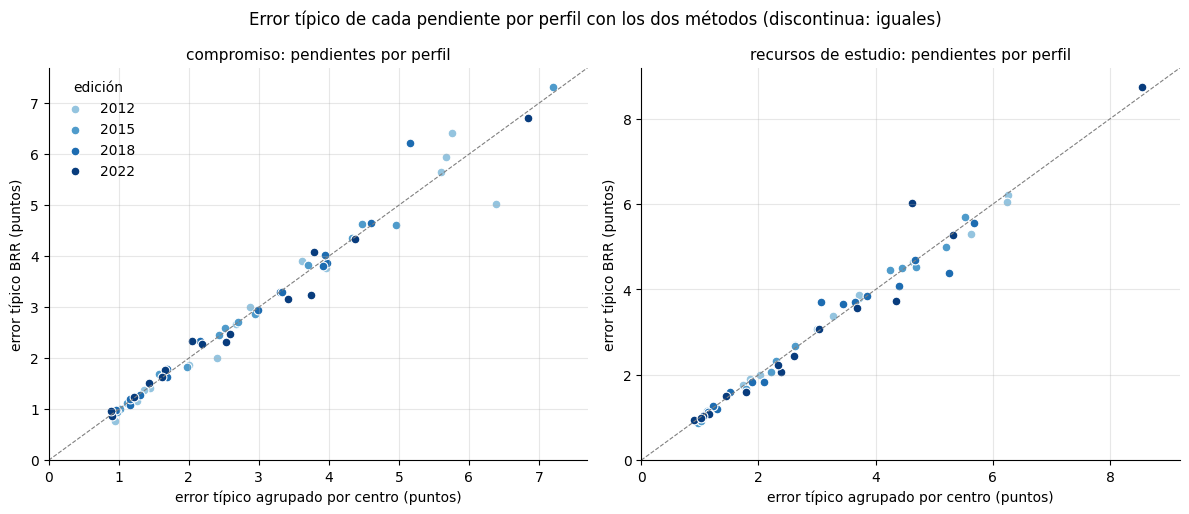

In [3]:
# Los dos modelos con los dos métodos de error típico
estimaciones = {}
for metodo in METODOS:
    replicas_metodo = replicas if metodo == 'brr' else None
    estimaciones[('comun', metodo)] = estimar_por_edicion(matriz, False, replicas=replicas_metodo)
    estimaciones[('perfil', metodo)] = estimar_por_edicion(matriz, True, replicas=replicas_metodo)

# Los coeficientes deben ser los mismos: solo cambia el error típico
diferencia = max((estimaciones[(especificacion, 'brr')][0]['coeficiente'] - estimaciones[(especificacion, 'centro')][0]['coeficiente']).abs().max()
                 for especificacion in ('comun', 'perfil'))
print(f'Mayor diferencia entre los coeficientes de los dos métodos: {diferencia:.2e} puntos')

# Error típico de cada pendiente de interés con los dos métodos y su cociente
filas = []
for especificacion in ('comun', 'perfil'):
    for metodo in METODOS:
        tabla_metodo = estimaciones[(especificacion, metodo)][0].reset_index()
        tabla_metodo['variable'] = tabla_metodo['termino'].str.split(':').str[0]
        tabla_metodo = tabla_metodo[tabla_metodo['variable'].isin(DE_INTERES)]
        filas.append(tabla_metodo.assign(especificacion=especificacion, metodo=metodo))
errores = (pd.concat(filas).pivot_table(index=['especificacion', 'variable', 'termino', 'year'], columns='metodo', values='error_tipico')
           .reset_index())
errores['cociente'] = errores['brr'] / errores['centro']

display(Markdown('**Pendiente común: coeficiente y error típico con cada método**'))
comun = errores[errores['especificacion'] == 'comun'].merge(estimaciones[('comun', 'centro')][0]['coeficiente'].reset_index(), on=['year', 'termino'])
display(comun.assign(variable=comun['variable'].map(NOMBRES)).set_index(['variable', 'year'])[['coeficiente', 'centro', 'brr', 'cociente']].round(3))

display(Markdown('**Cociente BRR / centro de los errores típicos de las pendientes por perfil**'))
por_perfil = errores[errores['especificacion'] == 'perfil']
display(por_perfil.groupby(['variable', 'year'])['cociente'].describe()[['count', 'min', '50%', 'max']].rename(index=NOMBRES, level='variable').round(3))
print(f"Pendientes por perfil: cociente mediano {por_perfil['cociente'].median():.3f}; entre 0,9 y 1,1 en {100 * por_perfil['cociente'].between(0.9, 1.1).mean():.1f} %;"
      f" por encima de 1,2 en {(por_perfil['cociente'] > 1.2).sum()} de {len(por_perfil)}")
display(Markdown('**Pendientes por perfil con el cociente más alejado de 1**'))
# Los cocientes más alejados de 1, en cualquier dirección (logaritmo)
extremos = por_perfil.assign(distancia=(np.log(por_perfil['cociente'])).abs()).nlargest(6, 'distancia')
display(extremos.set_index(['termino', 'year'])[['centro', 'brr', 'cociente']].round(3))

# Figura: error típico por centro frente a BRR de cada pendiente por perfil
fig, ejes = plt.subplots(1, 2, figsize=(12, 5.2))
for eje, variable in zip(ejes, DE_INTERES):
    filas_variable = por_perfil[por_perfil['variable'] == variable]
    for edicion in EDICIONES:
        filas_edicion = filas_variable[filas_variable['year'] == edicion]
        eje.scatter(filas_edicion['centro'], filas_edicion['brr'], s=40, color=COLORES_EDICION[edicion], edgecolor='white', linewidth=0.8, label=str(edicion))
    limite = 1.05 * filas_variable[['centro', 'brr']].max().max()
    eje.plot([0, limite], [0, limite], color='grey', linewidth=0.8, linestyle='--')
    eje.set_xlim(0, limite)
    eje.set_ylim(0, limite)
    eje.set_title(f'{NOMBRES[variable]}: pendientes por perfil', fontsize=11)
    eje.set_xlabel('error típico agrupado por centro (puntos)')
    eje.set_ylabel('error típico BRR (puntos)')
    eje.grid(alpha=0.3)
    eje.spines[['top', 'right']].set_visible(False)
ejes[0].legend(title='edición', frameon=False)
fig.suptitle('Error típico de cada pendiente por perfil con los dos métodos (discontinua: iguales)', fontsize=12)
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/03_errores_brr_comparacion.png', dpi=300, bbox_inches='tight')
plt.show()

**Qué se ve.**

* **Los coeficientes son los mismos con los dos métodos** (diferencia de 2,24e-11 puntos, redondeo numérico); solo cambia el error típico.
* **En la pendiente común, los dos errores casi coinciden.** El cociente BRR / centro va de 0,935 a 1,022. Por ejemplo, el compromiso en 2022 tiene 0,445 con los dos métodos, y los recursos de estudio en 2022, 0,465 por centro y 0,452 con BRR.
* **En las pendientes por perfil también.**
  * El cociente mediano es 0,996, y el 87,5 % está entre 0,9 y 1,1.
  * Los errores agrupados por centro no se quedan cortos de forma sistemática: unos son algo mayores que los de BRR y otros algo menores.
* **Las mayores diferencias están en perfiles pequeños y en las dos direcciones.**
  * Solo 3 de 120 cocientes pasan de 1,2. El mayor es el de los recursos del privado urbano pequeño en 2022 (4,61 por centro, 6,02 con BRR, 1,305).
  * El menor es el compromiso del concertado rural mediano en 2012 (0,786).
  * Son perfiles con pocos centros, donde las dos aproximaciones son menos estables.

## 3. Contrastes

Los errores pueden parecerse de uno en uno y diferir en un contraste conjunto, que usa también las covarianzas entre pendientes. Se repiten con los dos métodos los contrastes en los que se apoyan las conclusiones de `03_regresion_por_edicion`, con la misma regla de perfiles (fuera de los contrastes, los perfiles-edición con menos de 30 centros):

* el cambio de la pendiente común de 2012 a 2022;
* que las pendientes de los perfiles sean iguales en 2022;
* que su cambio de 2012 a 2022 sea igual en todos los perfiles;
* el cambio de la pendiente del privado urbano grande (`PRI_URB_MACRO`).

In [4]:
perfiles = sorted(matriz['perfil'].unique())
# Perfiles con al menos 30 centros en las dos ediciones (cambio) o en 2022 (igualdad en 2022)
fiables = [perfil for perfil in perfiles if not poco_representativo[(perfil, INICIO)] and not poco_representativo[(perfil, FINAL)]]
fiables_final = [perfil for perfil in perfiles if not poco_representativo[(perfil, FINAL)]]
# Los contrastes de `03_regresion_por_edicion`, repetidos con cada método
filas = []
for metodo in METODOS:
    comun_tabla, comun_covarianzas = estimaciones[('comun', metodo)]
    perfil_tabla, perfil_covarianzas = estimaciones[('perfil', metodo)]
    for variable in DE_INTERES:
        cambio, _ = cambio_entre_ediciones(comun_tabla, comun_covarianzas, [variable], INICIO, FINAL)
        _, (_, _, p_cambio_igual) = cambio_entre_ediciones(perfil_tabla, perfil_covarianzas, [f'{variable}:{perfil}' for perfil in fiables], INICIO, FINAL)
        _, _, p_final = contraste_igualdad(perfil_tabla.xs(FINAL, level='year')['coeficiente'], perfil_covarianzas[FINAL],
                                           [f'{variable}:{perfil}' for perfil in fiables_final])
        revisado, _ = cambio_entre_ediciones(perfil_tabla, perfil_covarianzas, [f'{variable}:{PERFIL_REVISADO}'], INICIO, FINAL)
        filas.append({'variable': NOMBRES[variable], 'metodo': METODOS[metodo], 'cambio': cambio['cambio'].iloc[0], 'error_cambio': cambio['error_tipico'].iloc[0],
                      'p_cambio': cambio['valor_p'].iloc[0], f'p_igualdad_perfiles_{FINAL}': p_final, 'p_igualdad_cambio': p_cambio_igual,
                      f'cambio_{PERFIL_REVISADO}': revisado['cambio'].iloc[0], f'error_{PERFIL_REVISADO}': revisado['error_tipico'].iloc[0],
                      f'p_{PERFIL_REVISADO}': revisado['valor_p'].iloc[0]})
contrastes = pd.DataFrame(filas).set_index(['variable', 'metodo'])
display(contrastes.round(3))

,,cambio,error_cambio,p_cambio,p_igualdad_perfiles_2022,p_igualdad_cambio,cambio_PRI_URB_MACRO,error_PRI_URB_MACRO,p_PRI_URB_MACRO
variable,metodo,,,,,,,,
compromiso,agrupados por centro,1.481,0.678,0.029,0.686,0.848,-1.634,3.683,0.657
recursos de estudio,agrupados por centro,0.458,0.702,0.514,0.003,0.032,14.256,4.471,0.001
compromiso,BRR,1.481,0.666,0.026,0.621,0.838,-1.634,3.544,0.645
recursos de estudio,BRR,0.458,0.674,0.497,0.000,0.012,14.256,4.573,0.002


**Qué se ve.** Con BRR, todas las conclusiones de `03_regresion_por_edicion` se mantienen, y las diferencias entre perfiles salen algo más claras:

* **El cambio del compromiso de 2012 a 2022** (+1,48) tiene un error de 0,666 con BRR y de 0,678 por centro (p = 0,026 y 0,029). Sigue siendo distinto de cero, con una significación igual de justa.
* **El cambio de los recursos de estudio** (+0,46) sigue sin distinguirse de cero (p = 0,497 con BRR, 0,514 por centro).
* **Las pendientes del compromiso son iguales entre perfiles**, en 2022 (p = 0,621 y 0,686) y en su cambio (p = 0,838 y 0,848).
* **Las de los recursos difieren entre perfiles.**
  * En 2022, p < 0,001 con BRR, frente a 0,003 por centro.
  * En su cambio desde 2012, p = 0,012 con BRR, frente a 0,032 por centro.
* **El privado urbano grande** sube 14,26 puntos, con un error de 4,573 con BRR y de 4,471 por centro (p = 0,002 y 0,001).

## Hallazgos

* **El cálculo de BRR reproduce las cifras oficiales de PISA**: la media de matemáticas de España y su error típico coinciden con los de la OCDE en 2012, 2015 y 2018.
* **Los errores típicos agrupados por centro son una buena aproximación a los de BRR en este modelo.**
  * En la pendiente común, el cociente entre los dos va de 0,935 a 1,022.
  * En las pendientes por perfil, la mediana es 0,996 y el 87,5 % está entre 0,9 y 1,1, sin que un método dé sistemáticamente errores mayores que el otro.
* **Ninguna conclusión cambia con BRR.**
  * La subida del compromiso sigue siendo justa (p = 0,026).
  * Los recursos de estudio siguen estables de media (p = 0,497).
  * Las pendientes del compromiso siguen siendo iguales entre perfiles.
  * Las de los recursos siguen difiriendo entre perfiles en 2022 (p < 0,001), y el privado urbano grande sigue subiendo (p = 0,002).
* **Por eso el resto del análisis usa los errores agrupados por centro.** Las comprobaciones de robustez (`03_robustez_regresion`) y `models/coeficientes_regresion.csv` usan esos errores. Este notebook justifica que la aproximación no cambia las conclusiones.

**Siguiente notebook**: `03_robustez_regresion`, que repite el modelo cambiando una decisión cada vez.